In [1]:
# Rucno importovanje ssp modula:
import sys
sys.path.insert(0, '/home/emir/Faks/SIS2/Knjiga_SIS2/Prilozi/SIS2_Kodovi/')
import ssp

# Importovanje ostalih biblioteka:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import hist

# Podesavanje prikaza za knjigu:
ssp.FORMATIRANJE_PRIKAZA = "BOOK"
ssp.REZOLUCIJA = "LOW"

# Podesavanje prikaza za rad studenata:
# ssp.FORMATIRANJE_PRIKAZA = "JUPYTER"
# ssp.REZOLUCIJA = "LOW"

In [2]:
#Programski kod 5.1

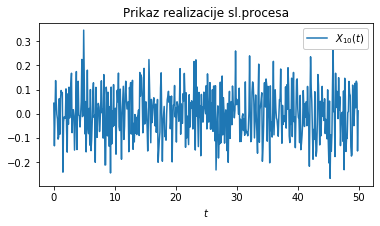

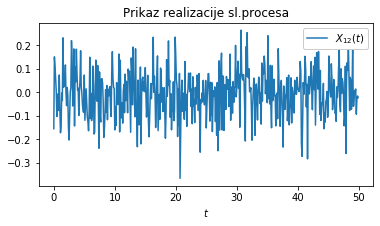

In [3]:
N = 500
M = 500

delta_t = 0.1
t = np.arange(0, N*delta_t, delta_t)

# Slucajni proces:
X_t = np.empty((M, N))

for k in range(M):
    X_t[k,:] = np.random.normal(0, 0.1, N)
    
#Crtanje realizacija slučajnog procesa X(t)
ssp.slproc.realizacije(t, X_t, indeksi = [10],
                          naslov = "Prikaz realizacije sl.procesa")
ssp.slproc.realizacije(t, X_t, indeksi = [12],
                          naslov = "Prikaz realizacije sl.procesa")

In [4]:
#Programski kod 5.2

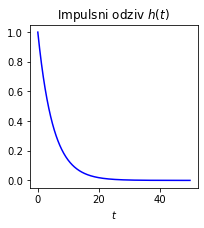

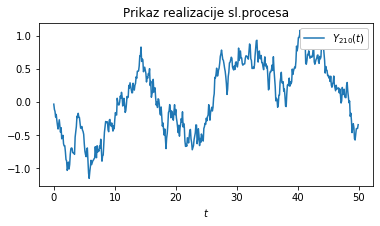

In [5]:
#Određivanja izlaza iz sistema sa impulsnim odzivom h(t)
h = np.exp(-t/5)
Y_t = np.empty((M,N))

for k in range(M):
    y = np.convolve(X_t[k, :], h)
    Y_t[k, :] = y[0:N] 

#Crtanje impulsnog odziva
ssp.slprom1D.grafik(t, h, 
                    naslov = "Impulsni odziv $h(t)$")

ssp.slproc.realizacije(t, Y_t, indeksi = [210], 
                           promjenljiva = 'Y',
                           naslov = "Prikaz realizacije sl.procesa")

In [6]:
#Programski kod 5.3

In [7]:
# Isječak koda:
def korelacija_stacionarna(R_xx, delta_t):
    # ...
    # Formiranje autokorelacione fje R(tau) (tau= t1-t2, za t2=0, tau ide od 0 do t1max)
    R_xx_tau = R[:, 0]
    # ...
    tau_vektor = np.arange(0, len(R_xx_tau) * delta_t, delta_t)
    # ...
    return tau_vektor, R_xx_tau


In [8]:
#Programski kod 5.4

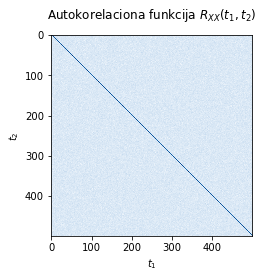

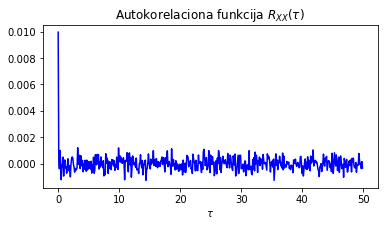

In [9]:
R_xx = ssp.slproc.korelacija(X_t,X_t,
                naslov = "Autokorelaciona funkcija $R_{XX}(t_1,t_2)$")

R_xx_tau = ssp.slproc.korelacija_stacionarna(R_xx, delta_t,
                naslov = "Autokorelaciona funkcija $R_{XX}(\\tau)$");

In [10]:
#Programski kod 5.5

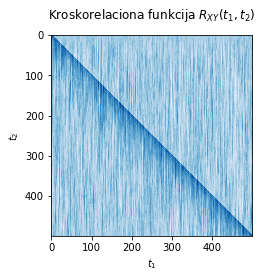

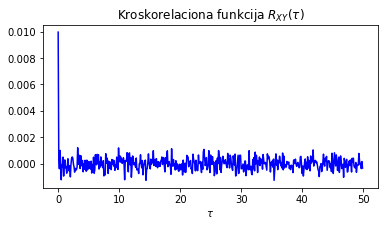

In [11]:
R_xy = ssp.slproc.korelacija(X_t,Y_t,
                                naslov = "Kroskorelaciona funkcija $R_{XY}(t_1,t_2)$")

R_xy_tau = ssp.slproc.korelacija_stacionarna(R_xy, delta_t,
                                naslov = "Kroskorelaciona funkcija $R_{XY}(\\tau)$");

In [12]:
#Programski kod 5.6

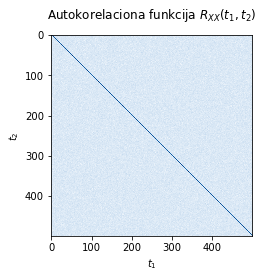

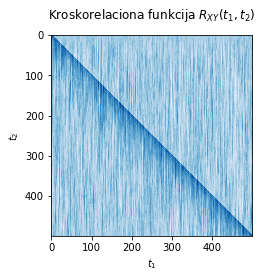

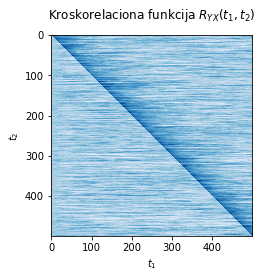

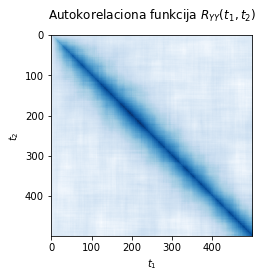

In [13]:
ssp.slproc.korelacija(X_t,X_t,
                          naslov = "Autokorelaciona funkcija $R_{XX}(t_1,t_2)$");

ssp.slproc.korelacija(X_t,Y_t,
                          naslov = "Kroskorelaciona funkcija $R_{XY}(t_1,t_2)$");

ssp.slproc.korelacija(Y_t,X_t,
                          naslov = "Kroskorelaciona funkcija $R_{YX}(t_1,t_2)$");

ssp.slproc.korelacija(Y_t,Y_t,
                          naslov = "Autokorelaciona funkcija $R_{YY}(t_1,t_2)$");

In [14]:
#Programski kod 5.7

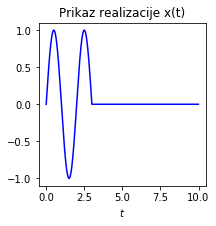

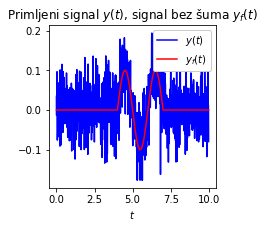

In [15]:
N = 1000
t = np.arange(0, 10, 10/N)  #Vrijeme

# Deterministički signal
x = np.sin(np.pi*t)*(np.heaviside(t, 1)-np.heaviside(t-3, 1))

# Šum
n = np.random.normal(0,0.05, N)

# Kašnjenje
T = 4

# Primljeni signal
y_bez_shuma = 0.1*np.roll(x, int(T*N/10))
y = y_bez_shuma + n

ssp.slprom1D.grafik(t,x, 
                 naslov = "Prikaz realizacije x(t)")

ssp.slprom1D.grafik(t, y, t, y_bez_shuma,  
                 naslov = 'Primljeni signal $y(t)$, signal bez šuma $y_{f}(t)$',
                 legenda = ['$y(t)$', '$y_{f}(t)$'])

In [16]:
#Programski kod 5.8

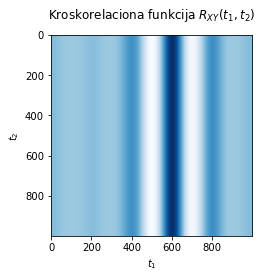

In [17]:
# Pravljenje procesa X(t) i Y(t)
M = len(x)

X_t = np.empty((M, N))
Y_t = np.empty((M, N))
Y_t2 = np.empty((M, N))
X_t2 = np.empty((M, N))

for k in range(M):
    X_t[k, :] = np.roll(x, k)
    # specificno! :
    Y_t[:,k] = np.flip(y)

R_xy = ssp.slproc.korelacija(X_t, Y_t,
                         naslov = "Kroskorelaciona funkcija $R_{XY}(t_1,t_2)$");

In [18]:
#Programski kod 5.9

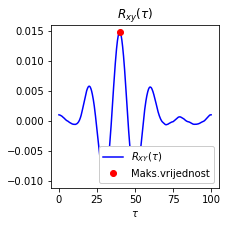

In [19]:
tau, R_xy_tau = ssp.slproc.korelacija_stacionarna(R_xy, delta_t,
                      prikaz = False)

R_xy_minus_tau = np.flip(R_xy_tau)    
maks_indeks = np.argmax(R_xy_minus_tau)

ssp.slprom1D.grafik(tau, R_xy_minus_tau, 
                    tau[maks_indeks], R_xy_minus_tau[maks_indeks], stil2='ro', 
                    naslov = '$R_{xy}(\\tau)$', x_labela = '$\\tau$',
                    legenda = ['$R_{XY}(\\tau)$', 'Maks.vrijednost'],
                    lokacija_lgd = 'lower right')

In [20]:
#Programski kod 5.10

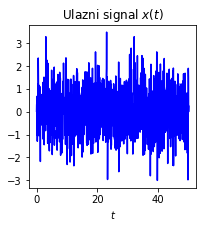

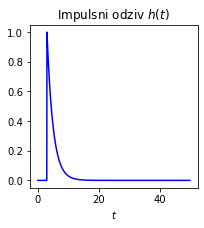

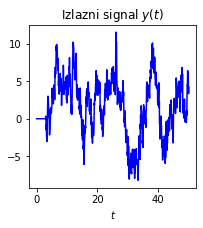

In [21]:
# Generiranje pobudnog signala - bijeli šum
N = 1000
trajanje = 50
t = np.arange(0, trajanje, trajanje/N)

# Pobudni signal
x = np.random.normal(0,1,N)

# Impulsni odziv
h = 1*np.exp (-(t-3)/2)*np.heaviside(t-3, 1)

# Izlazni signal
y = np.convolve(x,h)[0:N]

ssp.slprom1D.grafik(t, x, 
                 naslov = "Ulazni signal $x(t)$")
ssp.slprom1D.grafik(t, h, 
                 naslov = "Impulsni odziv $h(t)$")
ssp.slprom1D.grafik(t, y, 
                 naslov = "Izlazni signal $y(t)$")

In [22]:
#Programski kod 5.11

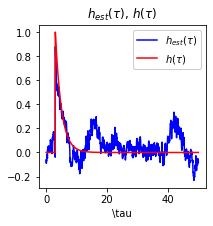

In [23]:
# Očekivana vrijednost h_est(Tau) = E[x(t-Tau)y(t)]
h_est = np.empty((N))

for Tau in range(N):
    h_est[Tau] = np.mean(np.roll(x, Tau)*y)

ssp.slprom1D.grafik(t, h_est, t, h,
                    naslov='$h_{est}(\\tau)$, $h(\\tau)$', 
                    x_labela= '\\tau', legenda = ['$h_{est}(\\tau)$', '$h(\\tau)$'])

In [24]:
#Programski kod 5.12

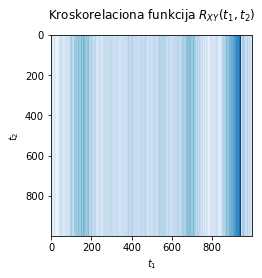

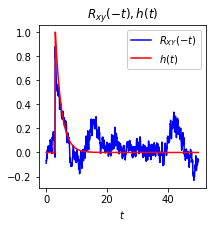

In [25]:
# h(tau)=R_xy(-tau)=R_xy(tmax,tmax-tau)

# Pravljenje procesa X(t) i Y(t)
M = len(x)

X_t = np.empty((M, N))
Y_t = np.empty((M, N))

for k in range(M):
    # specificno! :
    X_t[k, :] = np.roll(x, -k)
    Y_t[:,k] = y
       

R_xy = ssp.slproc.korelacija(X_t, Y_t,
                         naslov = "Kroskorelaciona funkcija $R_{XY}(t_1,t_2)$");

delta_t = t[1]-t[0]
tau_vektor, R_xy_tau = ssp.slproc.korelacija_stacionarna(R_xy, delta_t,
                      prikaz = False)

R_xy_minus_tau = np.flip(R_xy_tau, axis = 0)

ssp.slprom1D.grafik(tau_vektor, R_xy_minus_tau , t, h, 
                     naslov = '$R_{xy}(-t), h(t)$', 
                     legenda = ['$R_{XY}(-t)$', '$h(t)$'])